# Análise Exploratória de Dados — Mortalidade em SP, RJ e MG (SIM/DataSUS)

Análise das taxas de mortalidade por UF e município com os óbitos do SIM (Sistema de Informações
sobre Mortalidade) de São Paulo, Rio de Janeiro e Minas Gerais entre 2019 e 2022: 2,7 milhões de
óbitos de residentes em 1.590 municípios. A contagem de códigos distintos no extrato é 1.593
porque três códigos (330000, 310000 e 350000) são usados para município ignorado ou não
cadastrado na UF; sem eles, restam os 1.590 municípios.

**Variável central:** `taxa_por_100k` = óbitos × 100.000 / população, com a população estimada
pelo IBGE para o TCU (Tribunal de Contas da União).

> **Fonte dos dados:** recorte real do SIM/DataSUS (óbitos por município de residência) para
> SP, RJ e MG, agregado por município × ano × grupo CID-10 × sexo × faixa etária em
> `data/notebooks/sim_agregado.parquet`. O arquivo é gerado por
> `scripts/build_notebook_extract.py` a partir dos arquivos brutos do DataSUS, e as contagens
> batem com os microdados. População: estimativas IBGE/TCU
> (`backend/seeds/data/tcu_populacao.csv`). Todas as taxas são brutas, sem padronização por idade.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# Carregar população via pandas — DuckDB sniffer falha no em-dash UTF-8 do arquivo TCU
pop_df = pd.read_csv(
    '../backend/seeds/data/tcu_populacao.csv',
    skiprows=1,
    dtype={'codigo_ibge_6': str, 'ano': int, 'populacao_total': int}
)

con = duckdb.connect()  # in-memory — sem dependência de PostgreSQL
con.register('dim_populacao_csv', pop_df)

# Extrato real do SIM (SP, RJ e MG, 2015-2022), gerado por scripts/build_notebook_extract.py
OBITOS_PARQUET = '../data/notebooks/sim_agregado.parquet'
con.execute(f"""
    CREATE VIEW obitos AS
    SELECT * RENAME (municipio_codigo AS codigo_ibge_6) FROM read_parquet('{OBITOS_PARQUET}') WHERE ano BETWEEN 2019 AND 2022
""")

total_obitos, n_mun = con.execute(
    "SELECT SUM(obitos), COUNT(DISTINCT codigo_ibge_6) FROM obitos"
).fetchone()
print(f"Dados populacionais carregados: {len(pop_df):,} registros")
print(f"Óbitos SP + RJ + MG, 2019-2022: {total_obitos:,} em {n_mun} municípios de residência")

Dados populacionais carregados: 83,550 registros
Óbitos SP + RJ + MG, 2019-2022: 2,744,170 em 1593 municípios de residência


In [2]:
# Taxa de mortalidade anual por UF (óbitos por residência / população TCU)
df_uf_ano = con.execute("""
    WITH obitos_uf AS (
        SELECT sigla_uf, ano, SUM(obitos) AS total_obitos
        FROM obitos
        GROUP BY sigla_uf, ano
    ),
    pop_uf AS (
        SELECT
            CASE SUBSTRING(codigo_ibge_6, 1, 2) WHEN '35' THEN 'SP' WHEN '33' THEN 'RJ' ELSE 'MG' END AS sigla_uf,
            ano,
            SUM(populacao_total) AS pop_uf_total
        FROM dim_populacao_csv
        WHERE SUBSTRING(codigo_ibge_6, 1, 2) IN ('35', '33', '31')
        GROUP BY 1, 2
    )
    SELECT
        o.sigla_uf,
        o.ano,
        o.total_obitos,
        o.total_obitos * 100000.0 / p.pop_uf_total AS taxa_por_100k
    FROM obitos_uf o
    JOIN pop_uf p USING (sigla_uf, ano)
    ORDER BY o.sigla_uf, o.ano
""").df()

print(df_uf_ano.round(1).to_string(index=False))

sigla_uf  ano  total_obitos  taxa_por_100k
      MG 2019      141022.0          674.2
      MG 2020      152128.0          723.3
      MG 2021      190085.0          900.2
      MG 2022      162615.0          767.8
      RJ 2019      144600.0          841.0
      RJ 2020      172185.0          999.8
      RJ 2021      189232.0         1098.9
      RJ 2022      150806.0          876.2
      SP 2019      306190.0          675.8
      SP 2020      349635.0          768.0
      SP 2021      431616.0          945.4
      SP 2022      354056.0          774.1


## Taxa de Mortalidade por UF (2019–2022)

O efeito da COVID-19 domina o período, com pico em 2021 nas três UFs. Em SP a taxa sobe de 676
por 100 mil em 2019 para 945 em 2021 (+40%) e volta a 774 em 2022; em MG vai de 674 para 900
(+34%) e volta a 768. O RJ fica acima das outras duas em todos os anos (1.099 em 2021); parte
dessa diferença vem da estrutura etária, já que o RJ tem população mais envelhecida e as taxas
aqui não são padronizadas por idade.

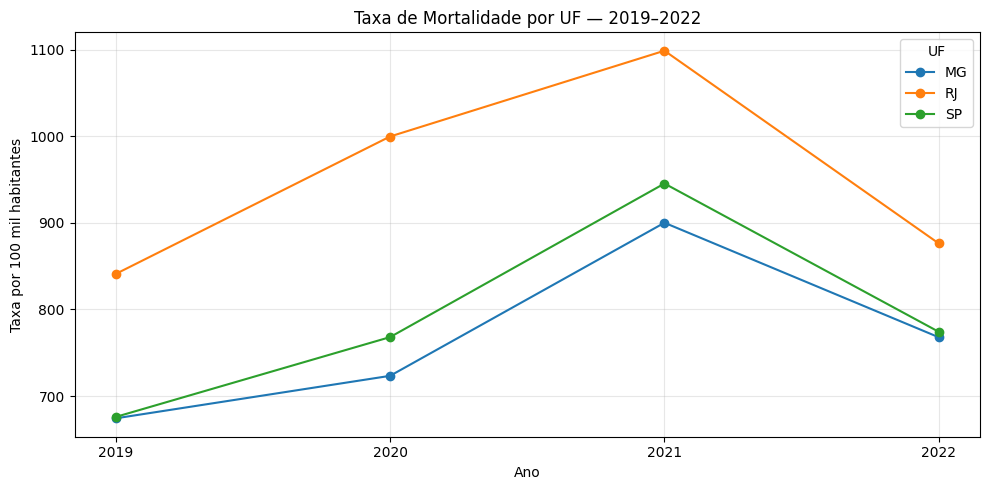

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

for uf, grp in df_uf_ano.groupby('sigla_uf'):
    ax.plot(grp['ano'], grp['taxa_por_100k'], marker='o', label=uf)

ax.set_xlabel('Ano')
ax.set_ylabel('Taxa por 100 mil habitantes')
ax.set_title('Taxa de Mortalidade por UF — 2019–2022')
ax.legend(title='UF')
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [4]:
# Distribuição por letra inicial da causa básica (CAUSABAS)
df_cid = con.execute("""
    SELECT capitulo_cid, SUM(obitos) AS total_obitos
    FROM obitos
    WHERE capitulo_cid IS NOT NULL
    GROUP BY capitulo_cid
    ORDER BY total_obitos DESC
""").df()
df_cid['pct'] = df_cid['total_obitos'] / df_cid['total_obitos'].sum()

# Letra inicial do código CID-10 -> grupo de causas
cid_chapters = {
    'A': 'Doenças infecciosas e parasitárias',
    'B': 'Doenças infecciosas e parasitárias (inclui COVID-19, B34.2)',
    'C': 'Neoplasias',
    'D': 'Neoplasias benignas / doenças do sangue',
    'E': 'Doenças endócrinas e metabólicas',
    'F': 'Transtornos mentais',
    'G': 'Doenças do sistema nervoso',
    'H': 'Olhos / ouvidos',
    'I': 'Doenças do aparelho circulatório',
    'J': 'Doenças do aparelho respiratório',
    'K': 'Doenças do aparelho digestivo',
    'L': 'Doenças da pele',
    'M': 'Doenças musculoesqueléticas',
    'N': 'Doenças do aparelho geniturinário',
    'O': 'Gravidez, parto e puerpério',
    'P': 'Afecções perinatais',
    'Q': 'Malformações congênitas',
    'R': 'Sintomas e sinais mal definidos',
    'V': 'Causas externas (transporte)',
    'W': 'Causas externas (quedas, afogamento etc.)',
    'X': 'Causas externas (inclui agressões)',
    'Y': 'Causas externas (outras)',
}
df_cid['descricao'] = df_cid['capitulo_cid'].map(cid_chapters).fillna(df_cid['capitulo_cid'])
top10 = df_cid.head(10)
print("Top-10 grupos CID-10 por total de óbitos (SP + RJ + MG, 2019-2022):")
print(top10.assign(pct=(top10['pct'] * 100).round(1))[['capitulo_cid', 'descricao', 'total_obitos', 'pct']]
      .to_string(index=False))

Top-10 grupos CID-10 por total de óbitos (SP + RJ + MG, 2019-2022):
capitulo_cid                                                   descricao  total_obitos  pct
           I                            Doenças do aparelho circulatório      668090.0 24.3
           C                                                  Neoplasias      414256.0 15.1
           B Doenças infecciosas e parasitárias (inclui COVID-19, B34.2)      352716.0 12.9
           J                            Doenças do aparelho respiratório      295200.0 10.8
           R                             Sintomas e sinais mal definidos      167011.0  6.1
           E                            Doenças endócrinas e metabólicas      140364.0  5.1
           K                               Doenças do aparelho digestivo      123674.0  4.5
           N                           Doenças do aparelho geniturinário      104521.0  3.8
           G                                  Doenças do sistema nervoso       87835.0  3.2
           A

## Distribuição por Grupo CID-10

Doenças do aparelho circulatório (I) lideram com 24,3% dos óbitos, seguidas de neoplasias (C,
15,1%). O terceiro lugar é do grupo B (12,9%), que normalmente fica perto de 1% do total: é ali
que o SIM registra a COVID-19 (código B34.2). A participação do grupo B passa de 1,3% em 2019
para 15,0% em 2020 e 25,3% em 2021, e cai para 5,9% em 2022.

O agrupamento usa a letra inicial do código CID-10. Para I (capítulo IX, I00–I99) e J (capítulo
X) a letra coincide com o capítulo; outras letras, como D e H, se dividem entre capítulos.

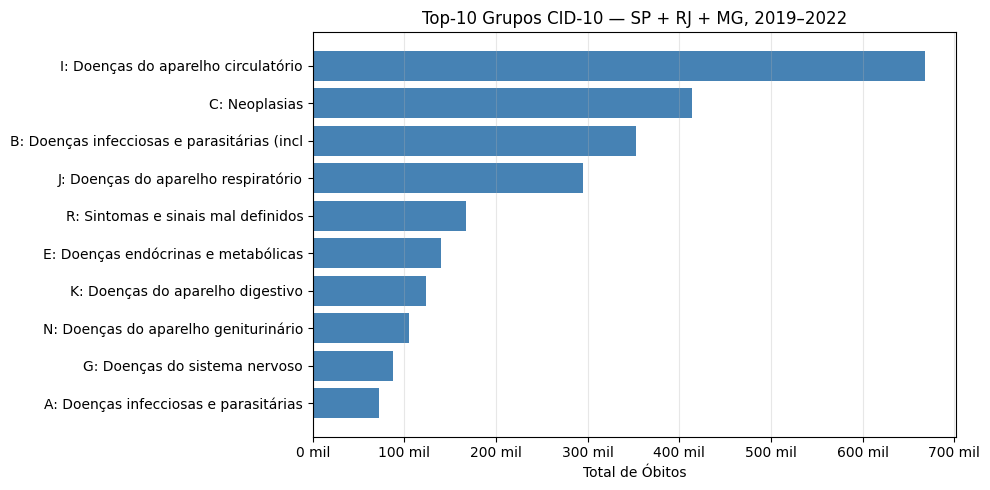

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

labels = [f"{row['capitulo_cid']}: {row['descricao'][:40]}" for _, row in top10.iterrows()]
ax.barh(labels[::-1], top10['total_obitos'].values[::-1], color='steelblue')
ax.set_xlabel('Total de Óbitos')
ax.set_title('Top-10 Grupos CID-10 — SP + RJ + MG, 2019–2022')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1000:.0f} mil'))
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
# Distribuição por faixa etária e sexo
# IDADE no SIM: primeiro dígito é a unidade (0-3 = menos de 1 ano, 4 = anos, 5 = 100+);
# o extrato já converte para faixas decenais e conta menores de 1 ano em 0-9.
ordem_faixas = ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59',
                '60-69', '70-79', '80-89', '90-99', '100+']

pivot = (
    con.execute("""
        SELECT faixa_etaria, sexo, SUM(obitos) AS obitos
        FROM obitos
        WHERE sexo IN ('M', 'F') AND faixa_etaria <> 'Ignorada'
        GROUP BY faixa_etaria, sexo
    """).df()
    .pivot(index='faixa_etaria', columns='sexo', values='obitos')
    .reindex(ordem_faixas)
    .rename(columns={'M': 'Masculino', 'F': 'Feminino'})
)

print("Distribuição por faixa etária e sexo:")
print(pivot.to_string())

Distribuição por faixa etária e sexo:
sexo          Feminino  Masculino
faixa_etaria                     
0-9            24507.0    29887.0
10-19           6562.0    16903.0
20-29          16963.0    51327.0
30-39          33427.0    68834.0
40-49          66412.0   114143.0
50-59         124839.0   204553.0
60-69         217038.0   311778.0
70-79         276716.0   325139.0
80-89         318786.0   259239.0
90-99         168576.0    86575.0
100+           12899.0     4092.0


## Distribuição por Faixa Etária e Sexo

A pirâmide mostra a sobremortalidade masculina nas idades jovens: entre 20 e 29 anos morrem
cerca de três homens para cada mulher (51 mil contra 17 mil), padrão típico de causas externas
como agressões e acidentes de trânsito. A partir dos 80 anos a relação se inverte, porque as
mulheres vivem mais e são maioria nessas faixas. Menores de 1 ano entram na faixa 0–9.

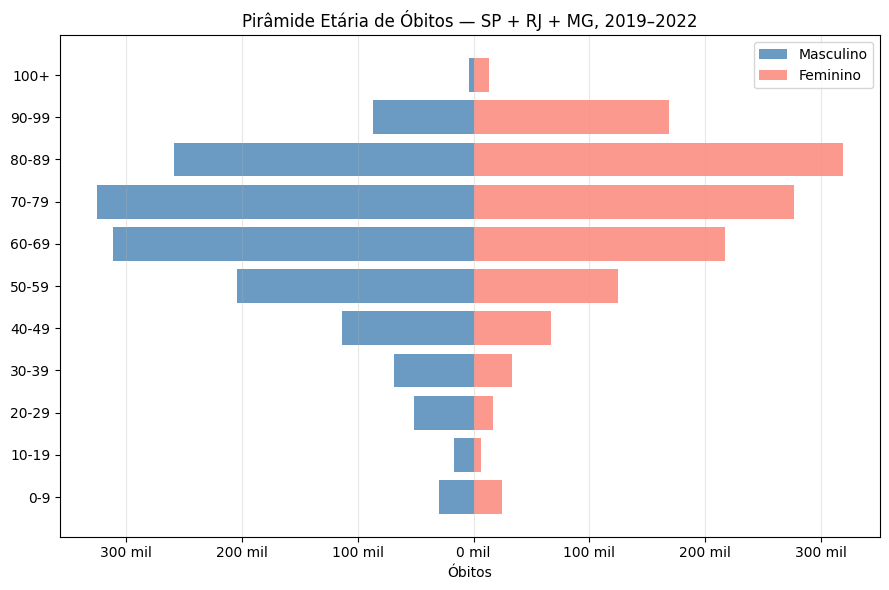

In [7]:
fig, ax = plt.subplots(figsize=(9, 6))

y_pos = range(len(pivot))
faixas = pivot.index.astype(str).tolist()

masc = pivot['Masculino'].values
fem = pivot['Feminino'].values

ax.barh(y_pos, -masc, label='Masculino', color='steelblue', alpha=0.8)
ax.barh(y_pos, fem, label='Feminino', color='salmon', alpha=0.8)

ax.set_yticks(list(y_pos))
ax.set_yticklabels(faixas)
ax.set_xlabel('Óbitos')
ax.set_title('Pirâmide Etária de Óbitos — SP + RJ + MG, 2019–2022')
ax.legend()

# Rótulos do eixo X sem sinal negativo
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{abs(x)/1000:.0f} mil'))
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Identificação de municípios com taxas atípicas (outliers geográficos)
# Taxa por município × ano comparada com a distribuição de todos os municípios de SP, RJ e MG
df_mun = con.execute("""
    WITH obitos_mun AS (
        SELECT codigo_ibge_6, ano, SUM(obitos) AS total_obitos
        FROM obitos
        GROUP BY codigo_ibge_6, ano
    )
    SELECT
        o.codigo_ibge_6,
        o.ano,
        o.total_obitos,
        p.populacao_total,
        o.total_obitos * 100000.0 / p.populacao_total AS taxa_por_100k
    FROM obitos_mun o
    JOIN dim_populacao_csv p
        ON o.codigo_ibge_6 = p.codigo_ibge_6 AND o.ano = p.ano
    WHERE p.populacao_total > 0
    ORDER BY o.codigo_ibge_6, o.ano
""").df()

print(f"Registros município×ano com população: {len(df_mun):,}")

# Outlier: taxa acima de média + 2 desvios-padrão
media_global = df_mun['taxa_por_100k'].mean()
std_global = df_mun['taxa_por_100k'].std()
limiar_outlier = media_global + 2 * std_global

print(f"\nTaxa média (município×ano): {media_global:.1f} por 100k")
print(f"Desvio padrão: {std_global:.1f}")
print(f"Limiar outlier (média + 2σ): {limiar_outlier:.1f}")

df_outliers = df_mun[df_mun['taxa_por_100k'] > limiar_outlier].copy()
print(f"\nMunicípios×Ano acima do limiar: {len(df_outliers)}")
print(f"População mediana dos outliers: {df_outliers['populacao_total'].median():,.0f} "
      f"(todos os municípios: {df_mun['populacao_total'].median():,.0f})")

Registros município×ano com população: 6,360

Taxa média (município×ano): 854.8 por 100k
Desvio padrão: 214.2
Limiar outlier (média + 2σ): 1283.1

Municípios×Ano acima do limiar: 206
População mediana dos outliers: 4,388 (todos os municípios: 10,663)


## Municípios com Taxas Atípicas

São 206 combinações município × ano acima de média + 2σ (1.283 por 100 mil), e elas se
concentram em municípios pequenos: a população mediana dos outliers é 4.388 habitantes, contra
10.663 no conjunto. Duas causas explicam a maior parte:

- **Denominador pequeno:** com 1.400 a 5.600 habitantes (o intervalo dos dez casos do topo), 20 ou
  30 óbitos a mais já movem a taxa em centenas de pontos.
- **Estrutura etária:** municípios pequenos do interior costumam ter população mais velha, e a
  taxa bruta não corrige isso.

A maioria dos casos do topo é de 2021, o ano de pico da pandemia.

In [9]:
# Top-10 município×ano com as maiores taxas
top_outliers = df_outliers.sort_values('taxa_por_100k', ascending=False).head(10)
print("Top-10 município×ano com maior taxa de mortalidade:")
print(top_outliers[['codigo_ibge_6', 'ano', 'total_obitos', 'populacao_total', 'taxa_por_100k']]
      .round(1).to_string(index=False))

Top-10 município×ano com maior taxa de mortalidade:
codigo_ibge_6  ano  total_obitos  populacao_total  taxa_por_100k
       350110 2021          88.0             3977         2212.7
       350060 2021          59.0             2857         2065.1
       354930 2022          46.0             2290         2008.7
       351580 2021          30.0             1549         1936.7
       314540 2022          38.0             1983         1916.3
       355695 2021          34.0             1821         1867.1
       330245 2021         105.0             5631         1864.7
       351580 2020          28.0             1574         1778.9
       355590 2019          24.0             1368         1754.4
       315880 2021          76.0             4341         1750.7


## Limitações

- **Taxas brutas:** sem padronização por idade, a comparação entre municípios mistura risco e
  estrutura etária. Uma análise de risco precisaria de taxas padronizadas.
- **Período atípico:** 2020 e 2021 são anos de pandemia, então variações entre anos refletem
  principalmente a COVID-19.
- **Recorte geográfico:** apenas SP, RJ e MG. O pipeline completo (`make full`) carrega todas as UFs.
- **Município de residência:** os óbitos são atribuídos ao município onde a pessoa morava, não
  onde morreu, o que reduz o viés de municípios com hospitais de referência.